## Setup

In [1]:
from statasetup import *


  ___  ____  ____  ____  ____ ®
 /__    /   ____/   /   ____/      StataNow 19.5
___/   /   /___/   /   /___/       BE—Basic Edition

 Statistics and Data Science       Copyright 1985-2025 StataCorp LLC
                                   StataCorp
                                   4905 Lakeway Drive
                                   College Station, Texas 77845 USA
                                   800-782-8272        https://www.stata.com
                                   979-696-4600        service@stata.com

Stata license: Unlimited-user network, expiring 17 Sep 2027
Serial number: 301909300944
  Licensed to: StataNow/BE 19.5
               TU/e

Notes:
      1. Unicode is supported; see help unicode_advice.


In [28]:
%%stata
use "Datasets\asg1\Roadlighting.dta",clear

## Step 1 - How to perform simple mediation analysis when exclusion of one categorical factor level is required?
the manual approach is rather meticulous since `a` `b` `c` and ` c' ` must be studied separately, by using distinct regression lines

**one must be sure** that there are no missing values in place

In [29]:
%%stata
* No missing values so we can proceed to creating the dummy variables
drop if safety ==.
drop if lightsetting ==.
drop if prospect ==. 

* or drop if safety == . | lightsetting == . | prospect == .



. * No missing values so we can proceed to creating the dummy variables
. drop if safety ==.
(0 observations deleted)

. drop if lightsetting ==.
(0 observations deleted)

. drop if prospect ==. 
(0 observations deleted)

. 
. * or drop if safety == . | lightsetting == . | prospect == .
. 


First of all, discard levels of particular categorical variables/mediators if any

In [30]:
%%stata
// as we will only look at spotlight vs the conventional lighting condition, we can get rid of condition 'darkspot' by deleting that data
drop if lightsetting==1
//generate a new dummy variable called spotlight with the conventional lighting as reference (coded 0)
gen spotlight = (lightsetting==2)   //spotlight gets value 1 if lightsetting==2 is true and 0 if false


. // as we will only look at spotlight vs the conventional lighting condition, 
> we can get rid of condition 'darkspot' by deleting that data
. drop if lightsetting==1
(167 observations deleted)

. //generate a new dummy variable called spotlight with the conventional lighti
> ng as reference (coded 0)
. gen spotlight = (lightsetting==2)   //spotlight gets value 1 if lightsetting=
> =2 is true and 0 if false

. 


**`a`** study

In [31]:
%%stata
* a (the first stage of the trajectory): M = I1 +x_light + error_1
reg prospect spotlight


. * a (the first stage of the trajectory): M = I1 +x_light + error_1
. reg prospect spotlight

      Source |       SS           df       MS      Number of obs   =       334
-------------+----------------------------------   F(1, 332)       =      7.12
       Model |  7.87931138         1  7.87931138   Prob > F        =    0.0080
    Residual |  367.651174       332  1.10738305   R-squared       =    0.0210
-------------+----------------------------------   Adj R-squared   =    0.0180
       Total |  375.530485       333  1.12771917   Root MSE        =    1.0523

------------------------------------------------------------------------------
    prospect | Coefficient  Std. err.      t    P>|t|     [95% conf. interval]
-------------+----------------------------------------------------------------
   spotlight |   .3071856   .1151611     2.67   0.008     .0806482     .533723
       _cons |   3.383353   .0814312    41.55   0.000     3.223167    3.543539
----------------------------------

**`b`** study - simpler than we expected so don't perceive the mediator's equivalent STATA syntax to be an INTERACTION as for moderated variables

the correct interpretation of c has at its core the part of the effect of i.v. on d.p. that is not account for by changes in the mediator can be seen above
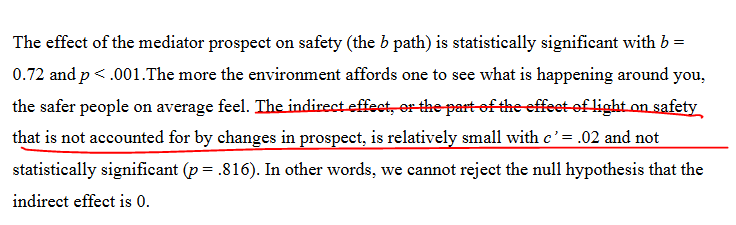

In [ ]:
%%stata
drop int_prospect_light
* b (the second stage of the trajectory): Y_safety = I1 +bM + x_lightC + error_2
reg safety spotlight prospect 


. drop int_prospect_light

. * b (the second stage of the trajectory): Y_safety = I1 +bM + x_lightC + erro
> r_2
. gen int_prospect_light = spotlight*prospect

. reg safety spotlight prospect 

      Source |       SS           df       MS      Number of obs   =       334
-------------+----------------------------------   F(2, 331)       =    194.71
       Model |  195.192058         2  97.5960288   Prob > F        =    0.0000
    Residual |  165.907266       331  .501230411   R-squared       =    0.5405
-------------+----------------------------------   Adj R-squared   =    0.5378
       Total |  361.099324       333  1.08438235   Root MSE        =    .70798

------------------------------------------------------------------------------
      safety | Coefficient  Std. err.      t    P>|t|     [95% conf. interval]
-------------+----------------------------------------------------------------
   spotlight |    .018273   .0783033     0.23   0.816    -.1357618    .1723079
    prospect |

**`c/the total effect`** study wherefrom the `c'` can be derived either directly from the regression table or by calculating c-ab=c'


In [36]:
%%stata
reg safety spotlight


      Source |       SS           df       MS      Number of obs   =       334
-------------+----------------------------------   F(1, 332)       =      4.46
       Model |  4.78323623         1  4.78323623   Prob > F        =    0.0355
    Residual |  356.316087       332  1.07324123   R-squared       =    0.0132
-------------+----------------------------------   Adj R-squared   =    0.0103
       Total |  361.099324       333  1.08438235   Root MSE        =     1.036

------------------------------------------------------------------------------
      safety | Coefficient  Std. err.      t    P>|t|     [95% conf. interval]
-------------+----------------------------------------------------------------
   spotlight |   .2393413   .1133719     2.11   0.036     .0163235    .4623592
       _cons |   3.323413    .080166    41.46   0.000     3.165716    3.481111
------------------------------------------------------------------------------


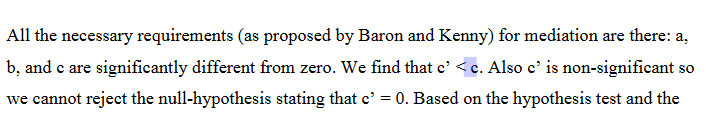